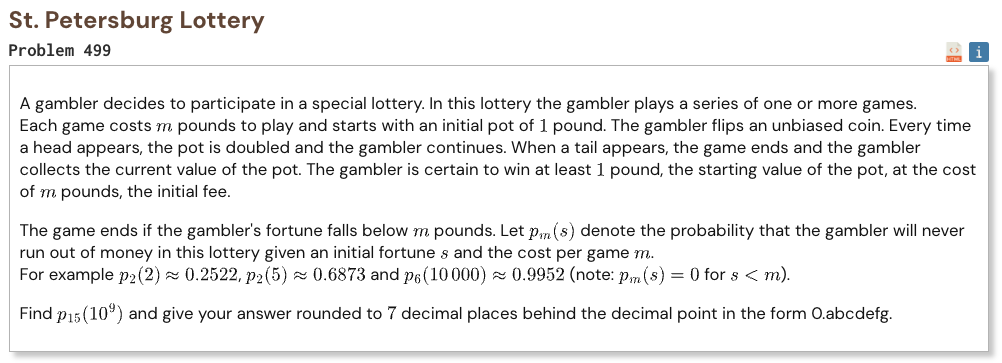

## Initial approach

- work with the probability of eventually going broke instead of surviving
- group fortunes into blocks because the same transition pattern repeats every 14 pounds
- represent transitions between these blocks with a small matrix
- ignore extremely large payouts whose total probability is far below the required precision
- solve the repeating matrix relation until it stabilizes
- solve one small linear system for fortunes near bankruptcy
- jump to the starting fortune with fast matrix exponentiation
- use numpy for the small matrix operations and linear system

In [1]:
%%time

import numpy as np

M = 15
START = 10**9
TAIL = 50
EPS = 1e-16

def survival_probability(cost, start):
    block = cost - 1

    probabilities = [
        2.0 ** (-(k + 1))
        for k in range(TAIL)
    ]

    payouts = [
        1 << k
        for k in range(TAIL)
    ]

    transitions = []
    needed_powers = set()

    for residue in range(block):
        row = []

        for payout, probability in zip(payouts, probabilities):
            layer = (residue + payout - 1) // block
            new_residue = (residue + payout - 1) % block

            row.append(
                (layer, new_residue, probability)
            )

            if layer > 0:
                needed_powers.add(layer)

        transitions.append(row)

    matrix = np.zeros(
        (block, block),
        dtype=float
    )

    for _ in range(500):
        powers = {
            power: np.linalg.matrix_power(
                matrix,
                power
            )
            for power in needed_powers
        }

        new_matrix = np.zeros_like(matrix)

        for residue, row in enumerate(transitions):
            for layer, new_residue, probability in row:
                if layer == 0:
                    new_matrix[
                        residue,
                        new_residue
                    ] += probability

                else:
                    new_matrix[residue] += (
                        probability
                        * powers[layer][new_residue]
                    )

        if np.max(
            np.abs(new_matrix - matrix)
        ) < EPS:
            matrix = new_matrix
            break

        matrix = new_matrix

    boundary = np.zeros(
        (block, block),
        dtype=float
    )

    ruin = np.zeros(
        block,
        dtype=float
    )

    boundary_transitions = []
    needed_powers = set()

    for residue in range(block):
        row = []

        for payout, probability in zip(payouts, probabilities):
            fortune = (
                residue
                + payout
                - block
            )

            if fortune <= 0:
                row.append(
                    (-1, 0, probability)
                )
                continue

            layer = (
                fortune - 1
            ) // block

            new_residue = (
                fortune - 1
            ) % block

            row.append(
                (layer, new_residue, probability)
            )

            if layer > 0:
                needed_powers.add(layer)

        boundary_transitions.append(row)

    powers = {
        power: np.linalg.matrix_power(
            matrix,
            power
        )
        for power in needed_powers
    }

    for residue, row in enumerate(
        boundary_transitions
    ):
        for layer, new_residue, probability in row:
            if layer == -1:
                ruin[residue] += probability

            elif layer == 0:
                boundary[
                    residue,
                    new_residue
                ] += probability

            else:
                boundary[residue] += (
                    probability
                    * powers[layer][new_residue]
                )

    base_ruin = np.linalg.solve(
        np.eye(block) - boundary,
        ruin
    )

    shifted = start - block

    layer = (
        shifted - 1
    ) // block

    residue = (
        shifted - 1
    ) % block

    final_ruin = (
        np.linalg.matrix_power(
            matrix,
            layer
        )
        @ base_ruin
    )[residue]

    return 1 - final_ruin

result = survival_probability(
    M,
    START
)

print("Result:", f"{result:.7f}")

Result: 0.8660313
CPU times: user 1.23 s, sys: 11 ms, total: 1.24 s
Wall time: 1.25 s
